<a href="https://colab.research.google.com/github/ughadeayush767-code/MDM-Machine-Learning/blob/main/Practical_No_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import plot_tree, DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [ ]:
data = pd.read_csv('Dataset 4.csv')

print("First five Records:")
print(data.head())
print("\nDataset Shape :", data.shape)

First five Records:
   Signal_Strength_dBm  SNR_dB  Interference_dB  Distance_m  Frequency_GHz  \
0                  -41       6                0         257            5.0   
1                  -86      25               20         134            2.4   
2                  -73      27                0         385            2.4   
3                  -57       5                0         255            5.0   
4                  -87      15               24          61            5.0   

   Channel_Bandwidth_MHz  Noise_Floor_dBm  Connected_Devices  \
0                    160             -100                 24   
1                    160              -96                 41   
2                     20              -72                 13   
3                    160              -86                  9   
4                     20              -79                 32   

   Estimated_Throughput_Mbps Quality  
0                         18    Poor  
1                         55    Poor  
2        

In [ ]:
x = data.drop("Quality", axis=1)
y = data["Quality"]

In [ ]:
encoder = LabelEncoder()
y = encoder.fit_transform(y)

print("\nClass Labels:")
print(encoder.classes_)


Class Labels:
['Excellent' 'Fair' 'Good' 'Poor']


In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.25, random_state=42, stratify=y
)

In [ ]:
dt = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)
dt.fit(x_train, y_train)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [ ]:
y_pred = dt.predict(x_test)

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy :{:.2f}%".format(accuracy * 100))


Accuracy :92.00%


In [ ]:
cn = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cn)


Confusion Matrix:
[[ 0  0  1  0]
 [ 0  8  1  0]
 [ 0  0  2  0]
 [ 0  0  0 13]]


In [ ]:
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=encoder.classes_,
    zero_division=0
))


Classification Report:
              precision    recall  f1-score   support

   Excellent       0.00      0.00      0.00         1
        Fair       1.00      0.89      0.94         9
        Good       0.50      1.00      0.67         2
        Poor       1.00      1.00      1.00        13

    accuracy                           0.92        25
   macro avg       0.62      0.72      0.65        25
weighted avg       0.92      0.92      0.91        25



In [ ]:
importance = pd.Series(dt.feature_importances_, index=x.columns)
importance = importance.sort_values(ascending=False)
print("\nFeature Importance:")
print(importance)


Feature Importance:
Signal_Strength_dBm          0.438873
SNR_dB                       0.365448
Estimated_Throughput_Mbps    0.117036
Interference_dB              0.078643
Distance_m                   0.000000
Frequency_GHz                0.000000
Channel_Bandwidth_MHz        0.000000
Noise_Floor_dBm              0.000000
Connected_Devices            0.000000
dtype: float64


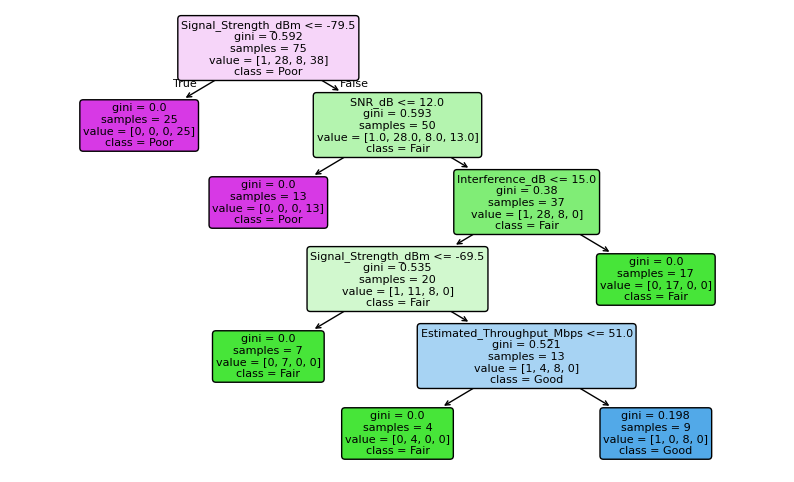

In [ ]:
plt.figure(figsize=(10, 6))
plot_tree(
    dt,
    filled=True,
    feature_names=x.columns,
    class_names=encoder.classes_,
    rounded=True,
    fontsize=8
)
plt.show()